In [7]:
import sys
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
import PIL
import sklearn
import matplotlib

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

keras.utils.set_random_seed(42)

CLASSES = ['cloudy', 'rain', 'shine', 'sunrise']
SIZE = (128, 128)

print('TensorFlow:', tf.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [8]:
from google.colab import drive

drive.mount('/content/drive_cuaca')
DRIVE = Path('/content/drive_cuaca/MyDrive')
RAW = DRIVE / 'DL' / 'dataset'
HASIL = DRIVE / 'DL' / 'hasil_sederhana'

if not DRIVE.is_dir():
    raise FileNotFoundError(
        'Google Drive belum berhasil terhubung.'
    )
print('Google Drive berhasil terhubung.')

if not RAW.is_dir():
    print('Isi MyDrive:')
    print([p.name for p in DRIVE.iterdir()])
    raise FileNotFoundError(
        f'Folder dataset tidak ditemukan: {RAW}'
    )
print('Folder dataset ditemukan:', RAW)

paths = sorted(
    p for p in RAW.rglob('*')
    if p.is_file()
    and p.suffix.lower() in ['.jpg', '.jpeg', '.png']
)
print('\nJumlah gambar:', len(paths))
print('Contoh gambar:', [p.name for p in paths[:5]])

if len(paths) == 0:
    print('Isi folder dataset:')
    print([p.name for p in list(RAW.iterdir())[:20]])
    raise ValueError(
        'Folder ditemukan tetapi gambar tidak terbaca.'
    )

HASIL.mkdir(parents=True, exist_ok=True)
print('\nDataset siap digunakan!')
print('Folder hasil:', HASIL)

Mounted at /content/drive_cuaca
Google Drive berhasil terhubung.
Folder dataset ditemukan: /content/drive_cuaca/MyDrive/DL/dataset

Jumlah gambar: 1125
Contoh gambar: ['cloudy1.jpg', 'cloudy10.jpg', 'cloudy100.jpg', 'cloudy101.jpg', 'cloudy102.jpg']

Dataset siap digunakan!
Folder hasil: /content/drive_cuaca/MyDrive/DL/hasil_sederhana


In [9]:
X, y = [], []
ukuran_asli = []
hash_terlihat = set()

rusak = 0
duplikat = 0
label_tidak_dikenali = 0

for path in paths:
    nama = path.stem.lower()
    folder = [p.lower() for p in path.parts[:-1]]

    label = next(
        (k for k in CLASSES
         if nama.startswith(k) or k in folder),
        None
    )

    if label is None:
        label_tidak_dikenali += 1
        continue

    try:
        file_hash = hashlib.md5(path.read_bytes()).hexdigest()

        if file_hash in hash_terlihat:
            duplikat += 1
            continue
        with Image.open(path) as img:
            ukuran_asli.append(img.size)
            img = img.convert('RGB').resize(SIZE)
            X.append(np.array(img, dtype='uint8'))

        y.append(CLASSES.index(label))
        hash_terlihat.add(file_hash)

    except Exception:
        rusak += 1

X = np.array(X, dtype='uint8')
y = np.array(y, dtype='int32')

print('Jumlah gambar valid:', len(y))
print('Gambar rusak:', rusak)
print('Duplikat identik:', duplikat)
print('Label tidak dikenali:', label_tidak_dikenali)
print('Ukuran gambar setelah resize:', X.shape)

if len(np.unique(y)) != 4:
    raise ValueError('Tidak semua empat kelas ditemukan.')

Jumlah gambar valid: 1099
Gambar rusak: 0
Duplikat identik: 26
Label tidak dikenali: 0
Ukuran gambar setelah resize: (1099, 128, 128, 3)


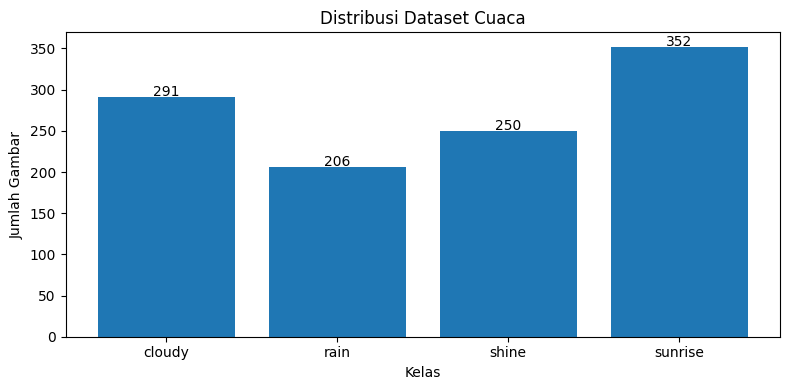

In [10]:
jumlah = [np.sum(y == i) for i in range(4)]

plt.figure(figsize=(8, 4))
plt.bar(CLASSES, jumlah)

plt.title('Distribusi Dataset Cuaca')
plt.xlabel('Kelas')
plt.ylabel('Jumlah Gambar')

for i, n in enumerate(jumlah):
    plt.text(i, n + 1, str(n), ha='center')

plt.tight_layout()
plt.savefig(HASIL / 'distribusi_kelas.png')
plt.show()

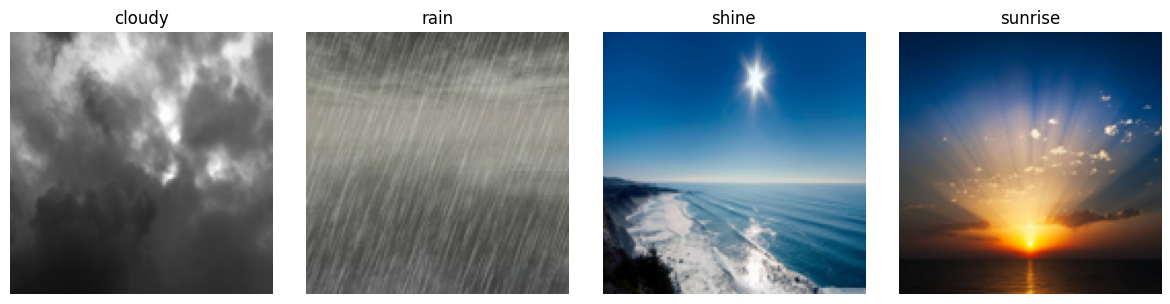

In [11]:
plt.figure(figsize=(12, 3))

for i in range(4):
    index = np.where(y == i)[0][0]

    plt.subplot(1, 4, i + 1)
    plt.imshow(X[index])
    plt.title(CLASSES[i])
    plt.axis('off')

plt.tight_layout()
plt.savefig(HASIL / 'contoh_kelas.png')
plt.show()

In [12]:
X_train, X_sisa, y_train, y_sisa = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_sisa, y_sisa,
    test_size=0.50,
    random_state=42,
    stratify=y_sisa
)

print('Training:', len(X_train))
print('Validation:', len(X_val))
print('Testing:', len(X_test))

print('Distribusi training:', np.bincount(y_train))
print('Distribusi validation:', np.bincount(y_val))
print('Distribusi testing:', np.bincount(y_test))

Training: 769
Validation: 165
Testing: 165
Distribusi training: [204 144 175 246]
Distribusi validation: [43 31 38 53]
Distribusi testing: [44 31 37 53]


In [13]:
keras.utils.set_random_seed(42)

HASIL_REVISI = Path(
    '/content/drive/MyDrive/DL/hasil_perbaikan'
)
HASIL_REVISI.mkdir(parents=True, exist_ok=True)

def buat_model(pakai_augmentasi=False):
    base = keras.applications.MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_shape=(128, 128, 3)
    )
    base.trainable = False
    inp = layers.Input(shape=(128, 128, 3))
    x = inp

    if pakai_augmentasi:
        x = layers.RandomFlip('horizontal')(x)
        x = layers.RandomRotation(0.05)(x)
        x = layers.RandomZoom(0.05)(x)

    x = layers.Rescaling(
        1 / 127.5, offset=-1
    )(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)

    output = layers.Dense(
        4, activation='softmax'
    )(x)

    model = keras.Model(inp, output)
    model.compile(
        optimizer=keras.optimizers.Adam(0.001),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model_A = buat_model(False)
model_A.summary()
print('Total parameter:', model_A.count_params())

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,263,108 (8.63 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Total parameter: 2263108


In [14]:
def latih_model(model):
    early_stop = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=4,
        restore_best_weights=True
    )
    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=18,
        batch_size=32,
        callbacks=[early_stop]
    )
    return history

print('=== MODEL A: TANPA AUGMENTASI ===')
keras.utils.set_random_seed(42)
history_A = latih_model(model_A)

print('=== MODEL B: DENGAN AUGMENTASI ===')
keras.utils.set_random_seed(42)
model_B = buat_model(True)

history_B = latih_model(model_B)
print('Training kedua model selesai.')

=== MODEL A: TANPA AUGMENTASI ===
Epoch 1/18
25/25 ━━━━━━━━━━━━━━━━━━━━ 27s 587ms/step - accuracy: 0.5982 - loss: 1.0577 - val_accuracy: 0.8727 - val_loss: 0.4779
Epoch 2/18
25/25 ━━━━━━━━━━━━━━━━━━━━ 19s 23ms/step - accuracy: 0.8466 - loss: 0.4181 - val_accuracy: 0.9030 - val_loss: 0.3015
Epoch 3/18
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.8895 - loss: 0.3145 - val_accuracy: 0.9394 - val_loss: 0.2420
Epoch 4/18
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.9233 - loss: 0.2305 - val_accuracy: 0.9515 - val_loss: 0.2039
Epoch 5/18
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9259 - loss: 0.2102 - val_accuracy: 0.9394 - val_loss: 0.1818
Epoch 6/18
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9506 - loss: 0.1621 - val_accuracy: 0.9394 - val_loss: 0.1661
Epoch 7/18
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9584 - loss: 0.1528 - val_accuracy: 0.9515 - val_loss: 0.1579
Epoch 8/18
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.9493 - lo

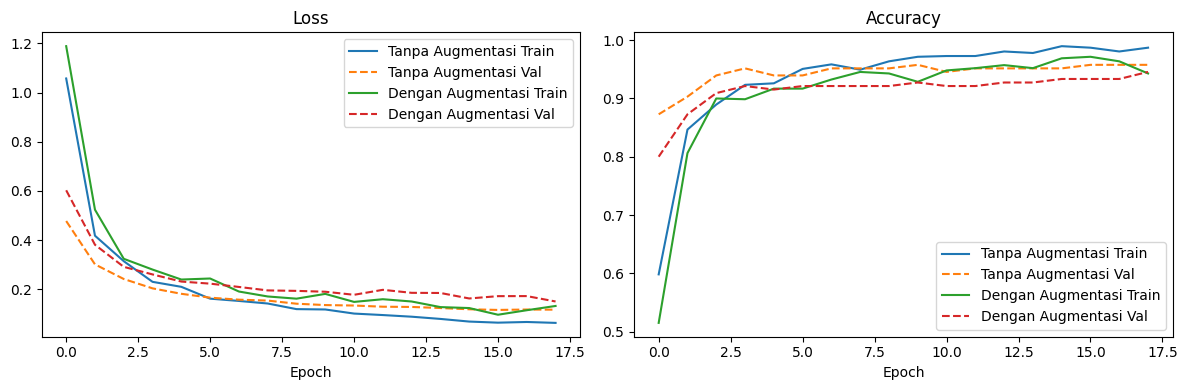

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for nama, history in [
    ('Tanpa Augmentasi', history_A),
    ('Dengan Augmentasi', history_B)
]:
    ax[0].plot(
        history.history['loss'],
        label=f'{nama} Train'
    )
    ax[0].plot(
        history.history['val_loss'],
        '--',
        label=f'{nama} Val'
    )
    ax[1].plot(
        history.history['accuracy'],
        label=f'{nama} Train'
    )
    ax[1].plot(
        history.history['val_accuracy'],
        '--',
        label=f'{nama} Val'
    )
ax[0].set_title('Loss')
ax[1].set_title('Accuracy')

for a in ax:
    a.set_xlabel('Epoch')
    a.legend()

plt.tight_layout()
plt.savefig(HASIL_REVISI / 'learning_curves.png')
plt.show()

In [16]:
loss_A = min(history_A.history['val_loss'])
loss_B = min(history_B.history['val_loss'])

if loss_A <= loss_B:
    model_terpilih = model_A
    nama_model = 'Tanpa Augmentasi'
else:
    model_terpilih = model_B
    nama_model = 'Dengan Augmentasi'
print('Model terpilih:', nama_model)

hasil = []

for nama, model in [
    ('Tanpa Augmentasi', model_A),
    ('Dengan Augmentasi', model_B)
]:
    prob_model = model.predict(X_test, verbose=0)
    pred_model = np.argmax(prob_model, axis=1)
    laporan = classification_report(
        y_test, pred_model,
        labels=[0, 1, 2, 3],
        target_names=CLASSES,
        output_dict=True,
        zero_division=0
    )
    hasil.append({
        'Model': nama,
        'Accuracy': accuracy_score(y_test, pred_model),
        'Precision': laporan['macro avg']['precision'],
        'Recall': laporan['macro avg']['recall'],
        'F1-Score': laporan['macro avg']['f1-score']
    })

hasil = pd.DataFrame(hasil)
display(hasil.round(4))
hasil.to_csv(
    HASIL_REVISI / 'hasil_testing.csv',
    index=False
)

prob_test = model_terpilih.predict(
    X_test, verbose=0
)
pred_test = np.argmax(prob_test, axis=1)
print('\nHasil model terpilih:')
print(classification_report(
    y_test, pred_test,
    target_names=CLASSES,
    zero_division=0
))

Model terpilih: Tanpa Augmentasi


,Model,Accuracy,Precision,Recall,F1-Score
0,Tanpa Augmentasi,0.9333,0.9391,0.9283,0.9326
1,Dengan Augmentasi,0.8970,0.9029,0.8877,0.8928



Hasil model terpilih:
              precision    recall  f1-score   support

      cloudy       0.89      0.93      0.91        44
        rain       0.97      0.94      0.95        31
       shine       0.97      0.86      0.91        37
     sunrise       0.93      0.98      0.95        53

    accuracy                           0.93       165
   macro avg       0.94      0.93      0.93       165
weighted avg       0.94      0.93      0.93       165



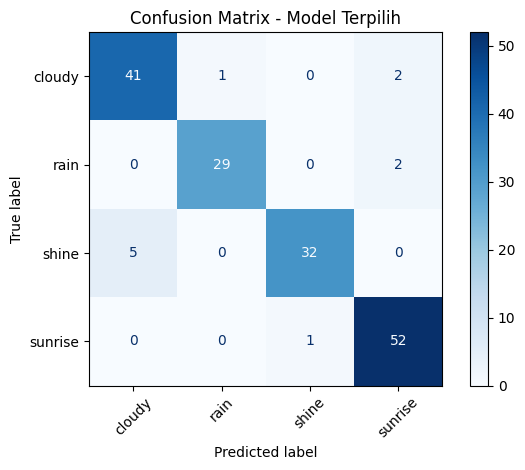

In [17]:
cm = confusion_matrix(
    y_test, pred_test,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)
disp.plot(cmap='Blues', xticks_rotation=45)

plt.title('Confusion Matrix - Model Terpilih')
plt.tight_layout()
plt.savefig(HASIL_REVISI / 'confusion_matrix.png')
plt.show()

In [18]:
confidence = np.max(prob_test, axis=1)

hasil_threshold = []

for threshold in [0.0, 0.75]:

    diterima = confidence >= threshold

    jumlah_diterima = np.sum(diterima)
    coverage = np.mean(diterima)

    if jumlah_diterima > 0:
        acc = accuracy_score(
            y_test[diterima],
            pred_test[diterima]
        )
    else:
        acc = np.nan

    hasil_threshold.append({
        'Threshold': threshold,
        'Diterima': jumlah_diterima,
        'Perlu Ditinjau': np.sum(~diterima),
        'Coverage': coverage,
        'Accuracy Diterima': acc
    })

hasil_threshold = pd.DataFrame(hasil_threshold)

display(hasil_threshold.round(4))

hasil_threshold.to_csv(
    HASIL_REVISI / 'hasil_threshold.csv',
    index=False
)

,Threshold,Diterima,Perlu Ditinjau,Coverage,Accuracy Diterima
0,0.00,165,0,1.0000,0.9333
1,0.75,147,18,0.8909,0.9660


Total testing: 165
Jumlah salah prediksi: 11


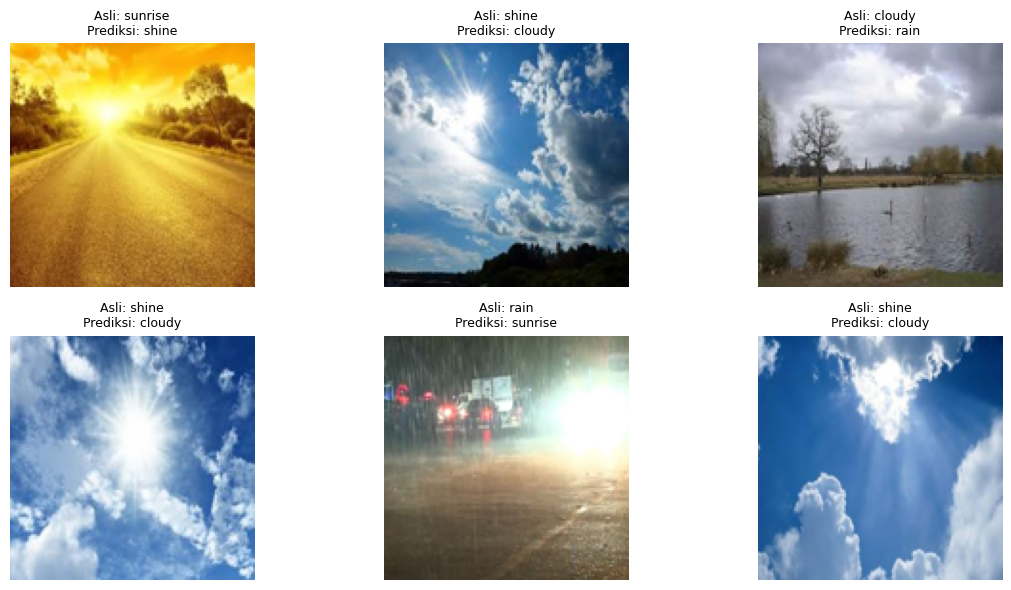

In [19]:
salah = np.where(pred_test != y_test)[0]

print('Total testing:', len(y_test))
print('Jumlah salah prediksi:', len(salah))

if len(salah) > 0:
    plt.figure(figsize=(12, 6))
    for i, index in enumerate(salah[:6]):
        plt.subplot(2, 3, i + 1)
        plt.imshow(X_test[index])
        asli = CLASSES[y_test[index]]
        prediksi = CLASSES[pred_test[index]]
        plt.title(
            f'Asli: {asli}\nPrediksi: {prediksi}',
            fontsize=9
        )
        plt.axis('off')

    plt.tight_layout()
    plt.savefig(
        HASIL_REVISI / 'contoh_kesalahan.png'
    )
    plt.show()
else:
    print('Tidak ada kesalahan pada data testing.')

In [20]:
model_terpilih.save(
    HASIL_REVISI / 'model_cuaca.keras'
)

print('Model revisi berhasil disimpan!')
print('Lokasi:', HASIL_REVISI)
print('Model:', nama_model)

Model revisi berhasil disimpan!
Lokasi: /content/drive/MyDrive/DL/hasil_perbaikan
Model: Tanpa Augmentasi


Label sebenarnya: Cloudy
Prediksi: cloudy
Confidence: 99.96%
cloudy: 99.96%
rain: 0.03%
shine: 0.01%
sunrise: 0.00%


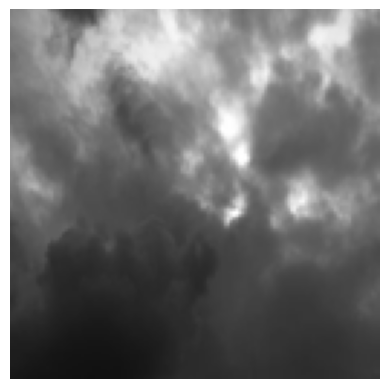

In [21]:
from PIL import Image

path = RAW / 'cloudy1.jpg'

with Image.open(path) as img:
    gambar = img.convert('RGB').resize((128, 128))

x = np.array(gambar)
x = np.expand_dims(x, axis=0)

prob_gambar = model_terpilih.predict(x, verbose=0)[0]

print('Label sebenarnya: Cloudy')
print('Prediksi:', CLASSES[np.argmax(prob_gambar)])
print('Confidence:', f'{np.max(prob_gambar):.2%}')

for nama, nilai in zip(CLASSES, prob_gambar):
    print(f'{nama}: {nilai:.2%}')

plt.imshow(gambar)
plt.axis('off')
plt.show()